# 00 · Tutorial: configurar a rede, os parâmetros e otimizar

Este notebook mostra como **definir uma rede de água de resfriamento do zero** com a API
Python do pacote `cwnet`, como todos os parâmetros do problema são configurados (fluido,
catálogo de diâmetros, bombas, trocadores, custos, cenários e opções do algoritmo), como
executar o estudo de projeto (tradicional + LP split-pipe por bomba), como ler os resultados
e como guardar/carregar o caso em YAML.

O método implementado é o de Souza et al. (2014) e a extensão multi-cenário de Costa,
Tonassi e Souza (2016); ver `docs/formulation.md` para o mapeamento equações ↔ código.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cwnet import load_case, run_design_study
from cwnet.reporting import plots, tables

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
CASES = Path("../cases")

## 1. Desenhar a rede (digrafo)

A rede é um digrafo: **nós** (vértices) e **arestas** orientadas no sentido do escoamento.
Cada aresta é uma tubulação, a bomba ou um trocador. O nó de suprimento (bacia da torre)
só tem arestas de saída e o nó de demanda (topo da torre) só tem arestas de entrada; os nós
de conexão referenciados pelas arestas são criados automaticamente.

Vamos construir uma rede pequena com 3 trocadores em paralelo.

In [2]:
from cwnet import (
    DesignCase, DesignOptions, Economics, Edge, Fluid, HeatExchanger, Network, Node,
    PipeCatalog, PipeSection, PumpCurve, PumpUnit, Scenario,
)

network = Network(
    nodes=[
        Node(id=1, tag="Bacia da torre", elevation=0.0, pressure=0.0),   # suprimento
        Node(id=8, tag="Topo da torre", elevation=6.0, pressure=0.0),    # demanda (6 m acima)
    ],
    edges=[
        Edge(id=1, tail=1, head=2),   # sucção
        Edge(id=2, tail=2, head=3),   # bomba
        Edge(id=3, tail=3, head=4),   # coletor de suprimento
        Edge(id=4, tail=4, head=5),   # ramal para E-1
        Edge(id=5, tail=4, head=6),   # ramal para E-2
        Edge(id=6, tail=4, head=7),   # ramal para E-3
        Edge(id=7, tail=5, head=9),   # E-1
        Edge(id=8, tail=6, head=10),  # E-2
        Edge(id=9, tail=7, head=11),  # E-3
        Edge(id=10, tail=9, head=12),
        Edge(id=11, tail=10, head=12),
        Edge(id=12, tail=11, head=12),
        Edge(id=13, tail=12, head=8), # coletor de retorno
    ],
)
print("nós:", network.node_ids)
print("suprimento:", network.supply_nodes(), "demanda:", network.demand_nodes())

nós: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
suprimento: [1] demanda: [8]


## 2. Elementos das arestas e parâmetros

* `PipeSection`: comprimento equivalente, rugosidade, L/D de acidentes, perda localizada fixa,
  `status` (`new` = diâmetro livre; `existing` = instalado, manter custa zero; `fixed` = imposto).
* `PumpUnit` + `pump_catalog`: a aresta da bomba e as alternativas comerciais (curva
  polinomial `H = a0 + a1 q + a2 q²`, eficiência, vazão nominal para o custo).
* `HeatExchanger`: vazão e perda de carga de projeto (curva `F = F_d (k/k_d)^1.8`) e,
  opcionalmente, os dados térmicos para a verificação ε-NTU.
* `PipeCatalog`: diâmetros comerciais candidatos (padrão: ASME B36.10 STD, 1/2" a 24").
* `Economics`: preço da energia, juros, horizonte, horas/ano, correlações de custo.
* `Scenario`: vazões demandadas por trocador (um ou vários cenários com frações de tempo).
* `DesignOptions`: velocidade máxima, válvulas, método tradicional, solver, etc.

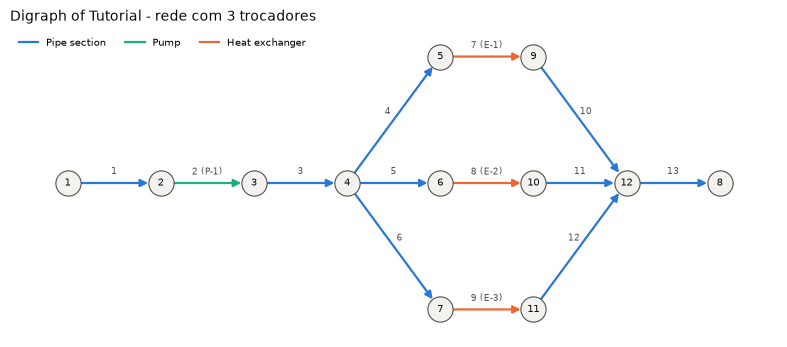

In [3]:
pipes = [
    PipeSection(edge=1, length=15.0),
    PipeSection(edge=3, length=120.0, fittings_ld=60.0),        # com acidentes (L/D = 60)
    PipeSection(edge=4, length=30.0),
    PipeSection(edge=5, length=45.0),
    PipeSection(edge=6, length=60.0),
    PipeSection(edge=10, length=30.0),
    PipeSection(edge=11, length=45.0),
    PipeSection(edge=12, length=60.0),
    PipeSection(edge=13, length=140.0),
]
exchangers = [
    HeatExchanger(edge=7, tag="E-1", design_flow=20.0, design_head_loss=4.5),
    HeatExchanger(edge=8, tag="E-2", design_flow=35.0, design_head_loss=6.0),
    HeatExchanger(edge=9, tag="E-3", design_flow=12.0, design_head_loss=3.0),
]
pump_catalog = [
    PumpCurve(tag="B-A", coefficients=[28.0, -120.0, -400.0], efficiency=0.62),
    PumpCurve(tag="B-B", coefficients=[34.0, -140.0, -450.0], efficiency=0.62),
    PumpCurve(tag="B-C", coefficients=[40.0, -160.0, -500.0], efficiency=0.62),
]
case = DesignCase(
    name="Tutorial - rede com 3 trocadores",
    fluid=Fluid(density=995.0, viscosity=0.72e-3),
    network=network,
    pipes=pipes,
    pump=PumpUnit(edge=2, tag="P-1"),
    pump_catalog=pump_catalog,
    exchangers=exchangers,
    pipe_catalog=PipeCatalog.ansi_b36_10_std(),
    economics=Economics(energy_price=0.08, interest_rate=0.10, project_years=15,
                        objective_basis="annualized"),
    scenarios=[Scenario(name="projeto", time_fraction=1.0,
                        flows={"E-1": 20.0, "E-2": 35.0, "E-3": 12.0})],
    options=DesignOptions(max_velocity=3.0, allow_valves=True, traditional_method="towler"),
)
ax = plots.plot_digraph(case)

## 3. Executar o estudo de projeto

`run_design_study` faz: balanço de massa (Eq. 6), circuitos hidráulicos (Eq. 10), coeficientes
de perda de carga, projeto tradicional (velocidade econômica), um LP por alternativa de bomba
(Eqs. 27-31/34-36), avaliação de custos e **simulação rigorosa** de cada projeto.

In [4]:
study = run_design_study(case, traditional_methods=["towler", "edgar_himmelblau"])
display(tables.mass_flow_table(study))
display(tables.cost_comparison_table(study))
print("melhor alternativa:", study.best.label)

,Edge,Mass flow rate (kg/s)
0,"1, 2, 3, 13",67.0
1,"5, 8, 11",35.0
2,"4, 7, 10",20.0
3,"6, 9, 12",12.0


,Methodology / case,Pump,Total cost (USD/y),Operational cost (USD/y),Pump cost (USD/y),Pipe cost (USD),Feasible
0,Traditional (towler),B-A,17771,13989,2624,8807,True
1,Traditional (edgar_himmelblau),B-A,17509,13964,2624,7007,True
2,Proposed / B-A,B-A,16767,13451,2624,5258,True
3,Proposed / B-B,B-B,20149,16740,2777,4811,True
4,Proposed / B-C,B-C,23574,20029,2915,4794,True


melhor alternativa: Proposed / B-A


,Edge,Traditional diameter (in),Optimization diameter (in),Optimization length fraction
0,1,12,8,1.000
1,3,12,8/10,0.790/0.210
2,4,6,4,1.000
3,5,8,6/8,0.678/0.322
4,6,5,3 1/2,1.000
5,10,6,4/5,0.869/0.131
6,11,8,6,1.000
7,12,5,3 1/2,1.000
8,13,12,8,1.000


,Heat exchanger,projeto (m)
0,E-1,0.0
1,E-2,0.0
2,E-3,0.0


,Edge,Length (m),Diameter (in),Length fraction,Mass flow (kg/s),Velocity (m/s),Head loss (m),Upstream pressure (bar g),Downstream pressure (bar g)
0,1,15.0,8,1.000,67.0,2.09,0.256,0.000,-0.025
1,3,120.0,8/10,0.790/0.210,67.0,2.09 / 1.32,1.915,1.742,1.555
2,4,30.0,4,1.000,20.0,2.45,1.595,1.555,1.400
3,5,45.0,6/8,0.678/0.322,35.0,1.89 / 1.09,0.668,1.555,1.490
4,6,60.0,3 1/2,1.000,12.0,1.89,2.274,1.555,1.333
5,10,30.0,4/5,0.869/0.131,20.0,2.45 / 1.56,1.453,0.960,0.819
6,11,45.0,6,1.000,35.0,1.89,0.880,0.905,0.819
7,12,60.0,3 1/2,1.000,12.0,1.89,2.274,1.041,0.819
8,13,140.0,8,1.000,67.0,2.09,2.386,0.819,0.000


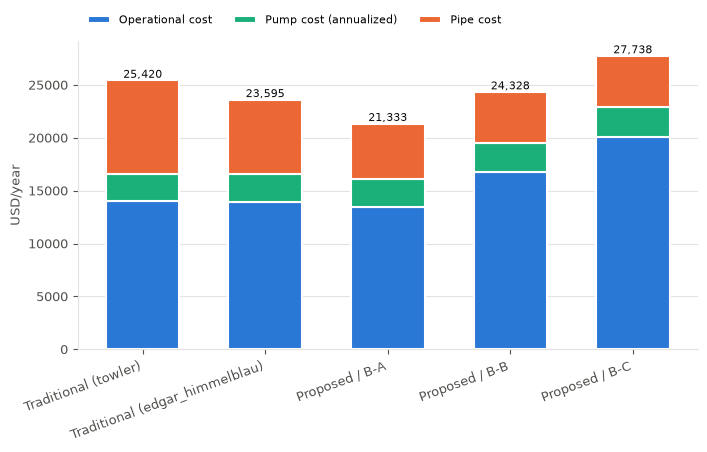

In [5]:
display(tables.design_comparison_table(study, traditional="towler"))
display(tables.valve_table(study.best, case))
display(tables.pipe_results_table(study.best, case))
ax = plots.plot_cost_comparison(study)

## 4. Alterar o desenho da rede e os parâmetros

Tudo é um objeto pydantic: podemos copiar o caso, inserir um trocador novo, mudar o catálogo,
fixar um diâmetro, declarar a bomba como existente, acrescentar cenários, etc.

,Methodology / case,Pump,Total cost (USD/y),Operational cost (USD/y),Pump cost (USD/y),Pipe cost (USD),Feasible
0,Traditional (towler),B-A,14973,13704,0,9658,True
1,Proposed / B-A,B-A,14897,13977,0,6999,True
2,Proposed / B-B,B-B,21124,17678,3009,3323,True
3,Proposed / B-C,B-C,24881,21379,3179,2456,True


,Edge,Diameter before revamp (in),Traditional diameter (in),Optimization diameter (in),Optimization length fraction
0,1,8,12,10,1.000
1,3,-,12,12,1.000
2,4,4,6,4,1.000
3,5,-,8,8,1.000
4,6,3 1/2,5,3 1/2/5,0.764/0.236
5,10,-,6,4/5,0.458/0.542
6,11,6,8,6,1.000
7,12,3 1/2,5,3 1/2,1.000
8,13,8,12,10/12,0.893/0.107
9,14,-,6,4/5,0.162/0.838


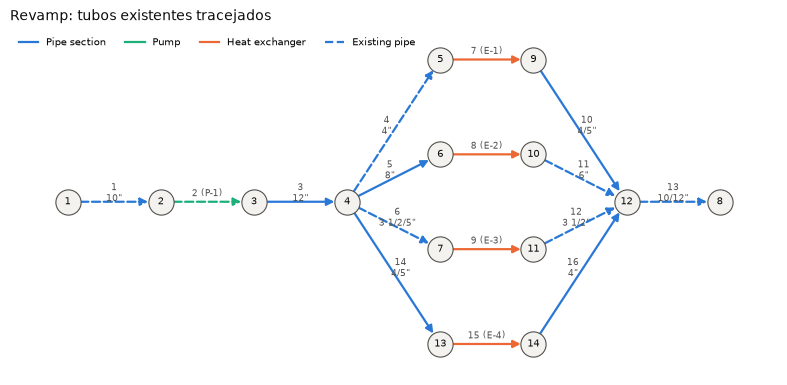

In [6]:
revamp = case.model_copy(deep=True)
# novo trocador E-4 em paralelo, alimentado por um ramal novo a partir do nó 4
revamp.network.edges += [Edge(id=14, tail=4, head=13), Edge(id=15, tail=13, head=14), Edge(id=16, tail=14, head=12)]
revamp.network = Network(nodes=revamp.network.nodes, edges=revamp.network.edges)  # revalida / cria nós novos
revamp.pipes += [PipeSection(edge=14, length=50.0), PipeSection(edge=16, length=50.0)]
revamp.exchangers.append(HeatExchanger(edge=15, tag="E-4", design_flow=18.0, design_head_loss=4.0))
# a rede existente foi construída com o projeto ótimo anterior: manter custa zero
best = study.best.design
for p in revamp.pipes:
    if p.edge in best.pipes and not best.pipes[p.edge].is_split:
        p.status = "existing"
        p.diameter = best.pipes[p.edge].labels(case)[0]
revamp.pump = PumpUnit(edge=2, tag="P-1", existing=True, curve=best.pump_curve)
revamp.scenarios = [Scenario(name="expansão", flows={"E-1": 20.0, "E-2": 35.0, "E-3": 12.0, "E-4": 18.0})]
revamp = DesignCase.model_validate(revamp.model_dump())
study2 = run_design_study(revamp, traditional_methods=["towler"])
ax = plots.plot_digraph(revamp, design=study2.best.design, title="Revamp: tubos existentes tracejados")
display(tables.cost_comparison_table(study2))
display(tables.design_comparison_table(study2, traditional="towler"))

## 5. Guardar e carregar em YAML; linha de comando

O caso completo pode ser guardado em YAML/JSON e editado à mão (ver `cases/*.yaml`, com
comentários em cada parâmetro). A CLI `cwnet` executa o mesmo estudo a partir do ficheiro.

In [7]:
from cwnet import save_case
save_case(revamp, "tutorial_revamp.yaml")
print(Path("tutorial_revamp.yaml").read_text()[:1200], "...")
again = load_case("tutorial_revamp.yaml")
assert again.model_dump() == revamp.model_dump()
Path("tutorial_revamp.yaml").unlink()

name: Tutorial - rede com 3 trocadores
description: ''
author: ''
date: ''
fluid:
  name: Cooling water
  density: 995.0
  viscosity: 0.00072
  heat_capacity: 4187.0
  inlet_temperature: 32.0
network:
  nodes:
  - id: 1
    tag: Bacia da torre
    elevation: 0.0
    pressure: 0.0
  - id: 2
    tag: ''
    elevation: 0.0
  - id: 3
    tag: ''
    elevation: 0.0
  - id: 4
    tag: ''
    elevation: 0.0
  - id: 5
    tag: ''
    elevation: 0.0
  - id: 6
    tag: ''
    elevation: 0.0
  - id: 7
    tag: ''
    elevation: 0.0
  - id: 8
    tag: Topo da torre
    elevation: 6.0
    pressure: 0.0
  - id: 9
    tag: ''
    elevation: 0.0
  - id: 10
    tag: ''
    elevation: 0.0
  - id: 11
    tag: ''
    elevation: 0.0
  - id: 12
    tag: ''
    elevation: 0.0
  - id: 13
    tag: ''
    elevation: 0.0
  - id: 14
    tag: ''
    elevation: 0.0
  edges:
  - id: 1
    from: 1
    to: 2
  - id: 2
    from: 2
    to: 3
  - id: 3
    from: 3
    to: 4
  - id: 4
    from: 4
    to: 5
  - id: 5
    f

In [8]:
import subprocess, sys
print(subprocess.run([sys.executable, "-m", "cwnet.cli", "--help"], capture_output=True, text=True).stdout)
print(subprocess.run([sys.executable, "-m", "cwnet.cli", "validate", str(CASES / "paper1_grassroots.yaml")],
                     capture_output=True, text=True).stdout)

usage: cwnet [-h] {validate,optimize,simulate,convert-legacy} ...

Cooling water pipe network design optimization

positional arguments:
  {validate,optimize,simulate,convert-legacy}
    validate            check a case file and its topology
    optimize            run the traditional and LP designs for every pump
    simulate            simulate the optimal design and print the hydraulic
                        results
    convert-legacy      convert a legacy Scilab caso*.txt file to YAML

options:
  -h, --help            show this help message and exit



Paper 1 - grassroots design of the cooling water network: 20 nodes, 23 edges, 17 pipes, 5 exchangers, 5 hydraulic circuits, 1 scenario(s) - OK

